In [1]:
import os
from google.colab import userdata

os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')

!kaggle datasets download -d navoneel/brain-mri-images-for-brain-tumor-detection --unzip -p ./brain-mri-images-for-brain-tumor-detection

Dataset URL: https://www.kaggle.com/datasets/navoneel/brain-mri-images-for-brain-tumor-detection
License(s): copyright-authors
100% 15.1M/15.1M [00:02<00:00, 7.58MB/s]



In [2]:
import time
import shutil
import pathlib
import itertools
from PIL import Image

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
sns.set_style('darkgrid')

In [5]:
data_dir = '/content/brain-mri-images-for-brain-tumor-detection'

In [6]:
filepaths = []
labels = []

folds = os.listdir(data_dir)
for fold in folds:
  foldpath = os.path.join(data_dir, fold)
  filelist = os.listdir(foldpath)
  for file in filelist:
    fpath = os.path.join(foldpath, file)

    filepaths.append(fpath)
    labels.append(fold)

In [7]:
fseries = pd.Series(filepaths, name = 'filepaths')
lseries = pd.Series(labels, name = 'labels')

df = pd.concat([fseries, lseries], axis = 1)

In [8]:
df

,filepaths,labels
0,/content/brain-mri-images-for-brain-tumor-dete...,brain_tumor_dataset
1,/content/brain-mri-images-for-brain-tumor-dete...,brain_tumor_dataset
2,/content/brain-mri-images-for-brain-tumor-dete...,no
3,/content/brain-mri-images-for-brain-tumor-dete...,no
4,/content/brain-mri-images-for-brain-tumor-dete...,no
...,...,...
250,/content/brain-mri-images-for-brain-tumor-dete...,yes
251,/content/brain-mri-images-for-brain-tumor-dete...,yes
252,/content/brain-mri-images-for-brain-tumor-dete...,yes
253,/content/brain-mri-images-for-brain-tumor-dete...,yes


In [9]:
from sklearn.model_selection import train_test_split
strat = df['labels']
train_df, test_df = train_test_split(df, train_size = 0.8, shuffle=True, random_state = 123, stratify = strat)

In [10]:
batch_size = 8
img_size = (224, 224)
channels = 3
img_shape = (img_size[0], img_size[1], channels)

In [11]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam, Adamax
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras import regularizers

In [12]:
tr_gen = ImageDataGenerator()
ts_gen = ImageDataGenerator()

In [23]:
train_gen = tr_gen.flow_from_dataframe(train_df, x_col = 'filepaths', y_col = 'labels', target_size = img_size, class_mode='categorical', color_mode='rgb', shuffle = True, batch_size=batch_size)
test_gen = ts_gen.flow_from_dataframe(test_df, x_col = 'filepaths', y_col = 'labels', target_size = 'img_size', class_mode='categorical', color_mode = 'rgb', shuffle = False, batch_size=batch_size)

Found 202 validated image filenames belonging to 2 classes.
Found 51 validated image filenames belonging to 2 classes.


/usr/local/lib/python3.13/dist-packages/keras/src/legacy/preprocessing/image.py:918: UserWarning: Found 2 invalid image filename(s) in x_col="filepaths". These filename(s) will be ignored.
  warnings.warn(


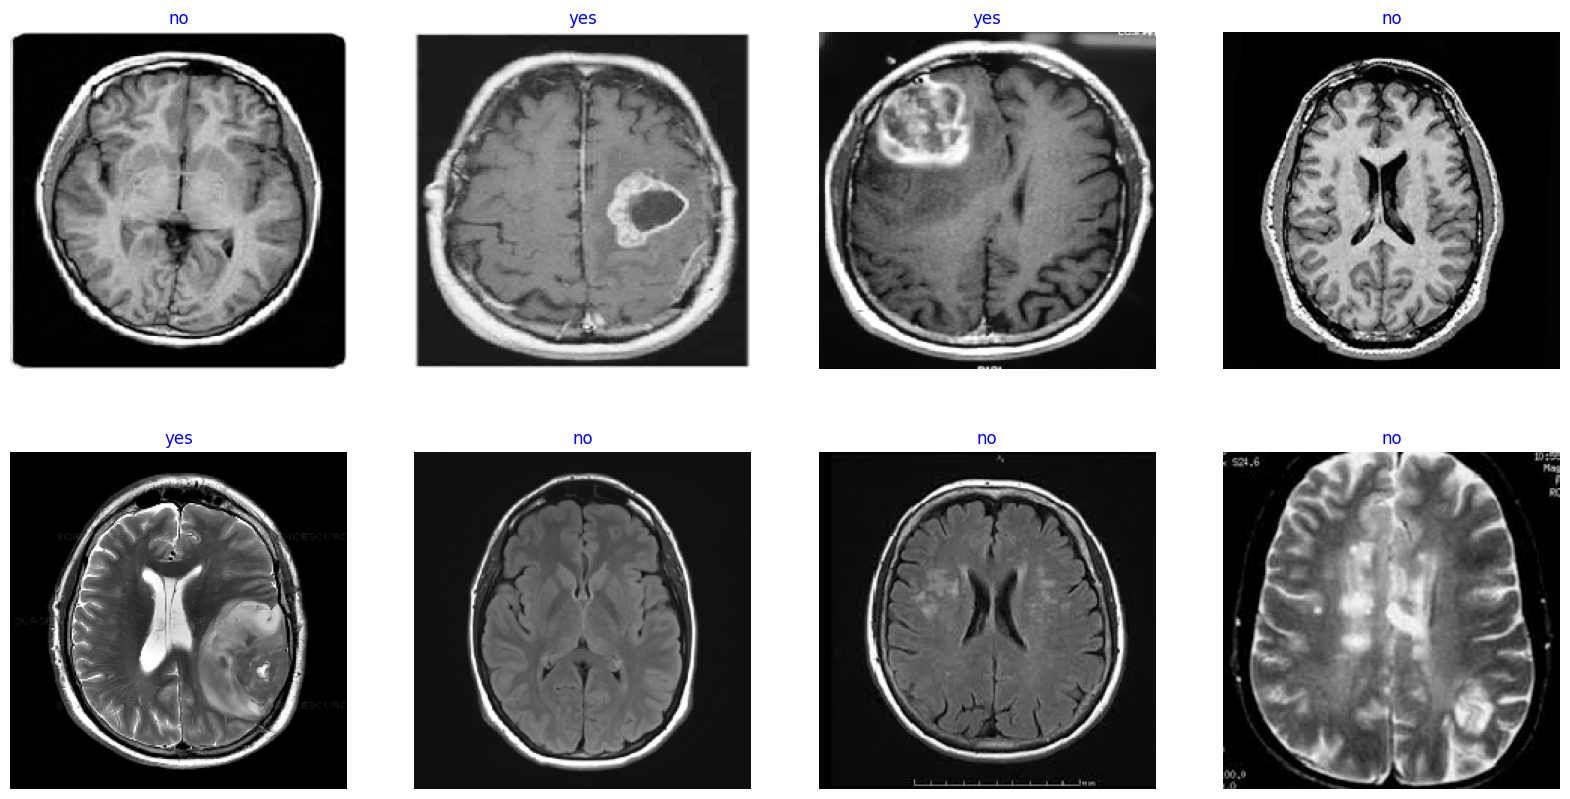

In [24]:
g_dict = train_gen.class_indices
classes = list(g_dict.keys())
images, labels = next(train_gen)
plt.figure(figsize=(20, 10))

for i in range (8):
  plt.subplot(2, 4, i + 1)
  image = images[i] / 255
  plt.imshow(image)
  index = np.argmax(labels[i])
  class_name = classes[index]
  plt.title(class_name, color = 'blue', fontsize = 12)
  plt.axis('off')
plt.show()

In [25]:
img_size = (224, 224)
channels = 3
img_shape = (img_size[0], img_size[1], channels)
class_count = len(list(train_gen.class_indices.keys()))


In [26]:
base_model = tf.keras.applications.efficientnet.EfficientNetB3(include_top = False, weights = 'imagenet', input_shape = img_shape, pooling = 'max')

In [27]:
model = Sequential([
base_model,
BatchNormalization(axis = -1, momentum=0.99, epsilon=0.001),
Dense(256, kernel_regularizer=regularizers.l2(0.016), activity_regularizer=regularizers.l1(0.006), bias_regularizer=regularizers.l1(0.006), activation = 'relu'),
Dropout(rate = 0.45, seed = 123),
Dense(class_count, activation = 'softmax')
])


In [28]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb3 (Functional)     │ (None, 1536)           │    10,783,535 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1536)           │         6,144 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       393,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,183,665 (42.66 MB)

 Trainable params: 11,093,290 (42.32 MB)

 Non-trainable params: 90,375 (353.03 KB)

In [29]:
model.compile(Adamax(learning_rate = 0.001), loss = 'binary_crossentropy', metrics = ['Accuracy'])

In [30]:

print("Training image shape:", train_gen.image_shape)
print("Training shape types:", [type(x) for x in train_gen.image_shape])

print("Test image shape:", test_gen.image_shape)
print("Test shape types:", [type(x) for x in test_gen.image_shape])


Training image shape: (224, 224, 3)
Training shape types: [<class 'int'>, <class 'int'>, <class 'int'>]
Test image shape: (224, 224, 3)
Test shape types: [<class 'int'>, <class 'int'>, <class 'int'>]


In [33]:

epochs = 30
history = model.fit(
    x=train_gen,
    validation_data=test_gen,
    epochs=epochs,
    verbose=1,
    validation_steps=None,
    shuffle=False
)


Epoch 1/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 90ms/step - Accuracy: 0.7822 - loss: 1.4291 - val_Accuracy: 0.7255 - val_loss: 1.3918
Epoch 2/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 86ms/step - Accuracy: 0.7475 - loss: 1.3918 - val_Accuracy: 0.8627 - val_loss: 1.3380
Epoch 3/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 87ms/step - Accuracy: 0.8366 - loss: 1.3508 - val_Accuracy: 0.8627 - val_loss: 1.3013
Epoch 4/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 87ms/step - Accuracy: 0.7871 - loss: 1.3016 - val_Accuracy: 0.7647 - val_loss: 1.2618
Epoch 5/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 88ms/step - Accuracy: 0.8366 - loss: 1.2605 - val_Accuracy: 0.8431 - val_loss: 1.2308
Epoch 6/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 90ms/step - Accuracy: 0.8416 - loss: 1.2236 - val_Accuracy: 0.8824 - val_loss: 1.1884
Epoch 7/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 90ms/step - Accuracy: 0.8317 - loss: 1.1774 - val_Accuracy: 0.8627 - val_loss: 1.1512
Epoch 8/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 91ms/step - Accuracy: 0.8614 - loss: 1.1352 - val_Accuracy: 0.8627 - v

In [36]:
tr_acc = history.history['Accuracy']
tr_loss = history.history['loss']
val_acc = history.history['val_Accuracy']
val_loss = history.history['val_loss']
index_loss = np.argmin(val_loss)
val_lowest = val_loss[index_loss]
index_acc = np.argmax(val_acc)
acc_heighest = val_acc[index_acc]
Epochs = [ i + 1 for i in range(len(tr_acc))]
loss_label = f'best epoch = {str(index_loss + 1)}'
acc_label = f'best epoch = {str(index_acc + 1)}'

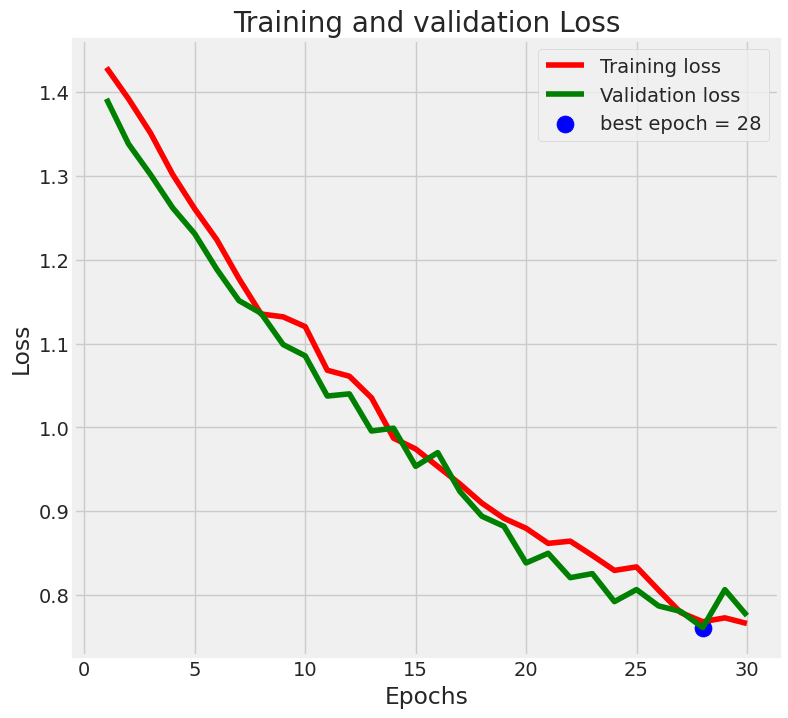

In [37]:
plt.figure(figsize = (20, 8))
plt.style.use('fivethirtyeight')

plt.subplot(1, 2, 1)
plt.plot(Epochs, tr_loss, 'r', label = 'Training loss')
plt.plot(Epochs, val_loss, 'g', label = 'Validation loss')
plt.scatter(index_loss + 1, val_lowest, s = 150, c = 'blue', label = loss_label)
plt.title('Training and validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

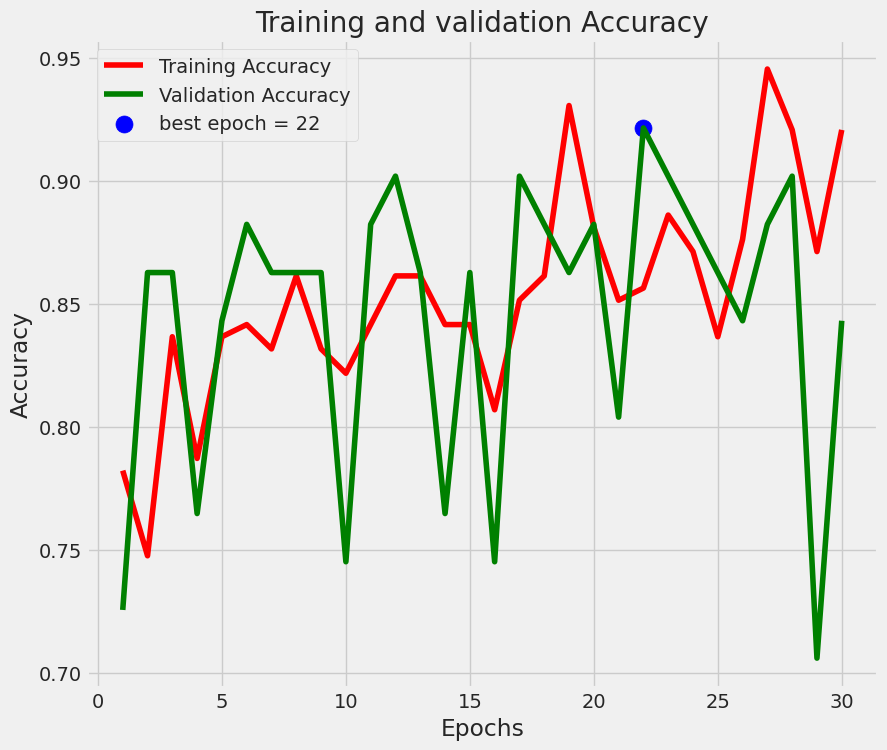

In [38]:
plt.figure(figsize = (20, 8))
plt.style.use('fivethirtyeight')

plt.subplot(1, 2, 2)
plt.plot(Epochs, tr_acc, 'r', label = 'Training Accuracy')
plt.plot(Epochs, val_acc, 'g', label = 'Validation Accuracy')

plt.scatter(index_acc + 1, acc_heighest, s = 150, c = 'blue', label = acc_label)

plt.title('Training and validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.legend()
plt.tight_layout
plt.show()

In [39]:
train_score = model.evaluate(train_gen)
test_score = model.evaluate(test_gen)

print('Train Loss', train_score[0])
print('Train Accuracy', train_score[1])
print('_' *  20)
print('Test Loss:', test_score[0])
print('Test Accuracy:', test_score[1])

26/26 ━━━━━━━━━━━━━━━━━━━━ 8s 331ms/step - Accuracy: 0.9851 - loss: 0.6845
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - Accuracy: 0.8431 - loss: 0.7755
Train Loss 0.6845017075538635
Train Accuracy 0.9851484894752502
____________________
Test Loss: 0.7754901051521301
Test Accuracy: 0.843137264251709


In [41]:
preds = model.predict_generator(test_gen)
y_pred = np.argmax(preds, axis = 1)

7/7 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step


In [42]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score


In [43]:
g_dict = test_gen.class_indices
classes = list(g_dict.keys())


In [45]:
cm = confusion_matrix(test_gen.classes, y_pred)
print(cm)

[[15  5]
 [ 3 28]]


In [46]:
accuracy_score(test_gen.classes, y_pred)

0.8431372549019608

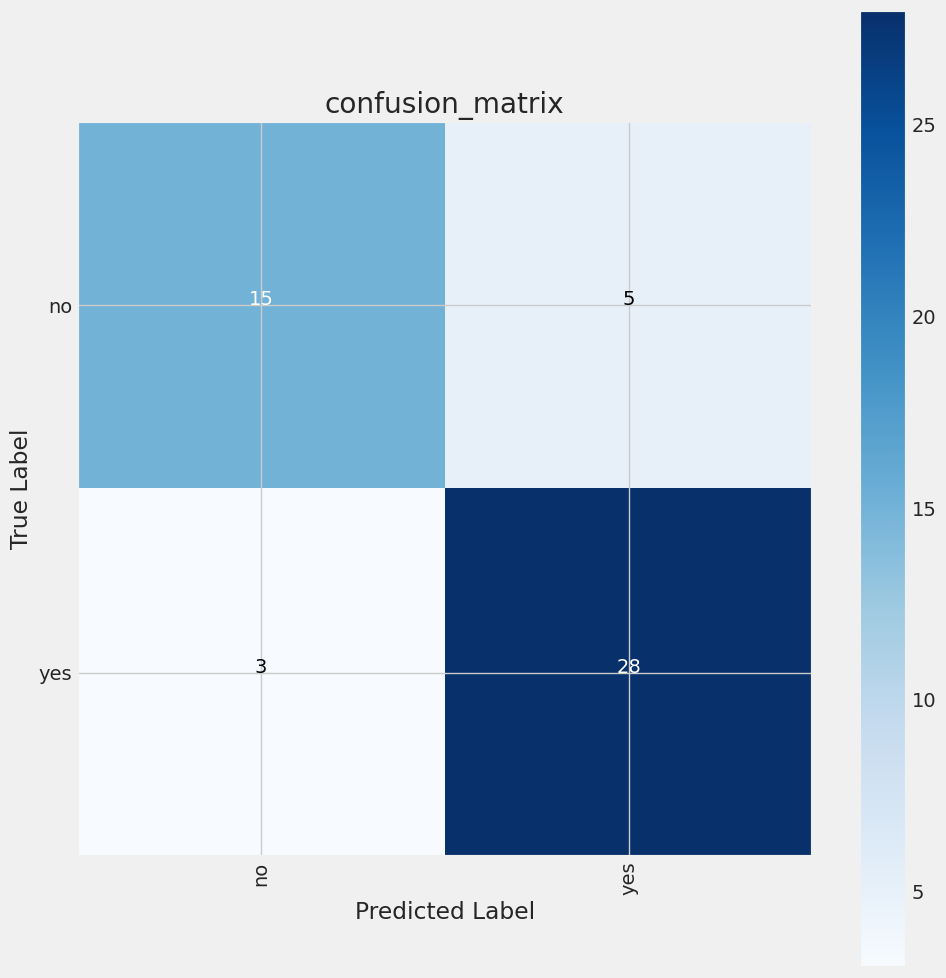

In [48]:
plt.figure(figsize = (10, 10))
plt.imshow(cm, interpolation='nearest', cmap = plt.cm.Blues)
plt.title('confusion_matrix')
plt.colorbar()

ticks_marks = np.arange(len(classes))
plt.xticks(ticks_marks, classes, rotation = 90)
plt.yticks(ticks_marks, classes)

thresh = cm.max() / 2
for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
  plt.text(j, i, cm[i, j], horizontalalignment = 'center', color = 'white' if cm[i, j] > thresh else 'black')
plt.tight_layout()
plt.ylabel('True Label')
plt.xlabel('Predicted Label')

plt.show()


In [49]:
print(classification_report(test_gen.classes, y_pred, target_names = classes))

              precision    recall  f1-score   support

          no       0.83      0.75      0.79        20
         yes       0.85      0.90      0.88        31

    accuracy                           0.84        51
   macro avg       0.84      0.83      0.83        51
weighted avg       0.84      0.84      0.84        51



In [50]:
import cv2

In [63]:
test_img = cv2.imread('/content/brain_tumor.webp')

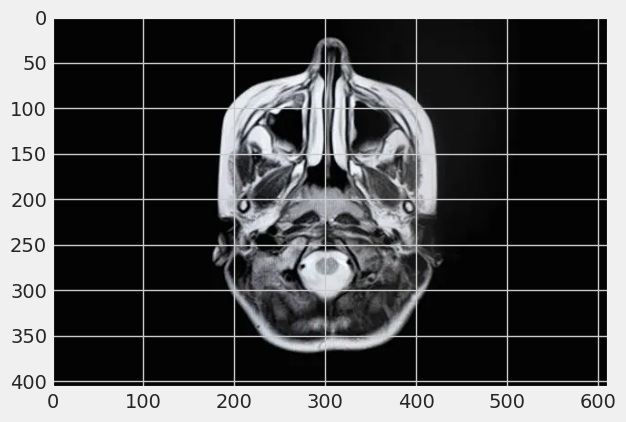

In [64]:
plt.imshow(test_img)

In [65]:
test_img.shape

(408, 612, 3)

In [66]:
test_img = cv2.resize(test_img, (224, 224))

In [67]:
test_input = test_img.reshape((1, 224, 224, 3))

In [68]:
model.predict(test_input)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step


array([[0.9812827 , 0.01871731]], dtype=float32)